# Dependencies

In [33]:
import pandas as pd 
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [34]:
! pip install scipy


In [35]:
data = pd.read_csv('train.csv', usecols=['Age','Fare','Survived'])

In [36]:
data.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [37]:
data.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [38]:
data['Age'] = data['Age'].fillna(data['Age'].mean())

In [39]:
data.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [40]:
data.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [41]:
x = data.iloc[: ,1:3]
y= data.iloc[: , 0]

In [42]:
x.head(3)

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250


In [43]:
y.head(3)

0    0
1    1
2    1
Name: Survived, dtype: int64

In [44]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

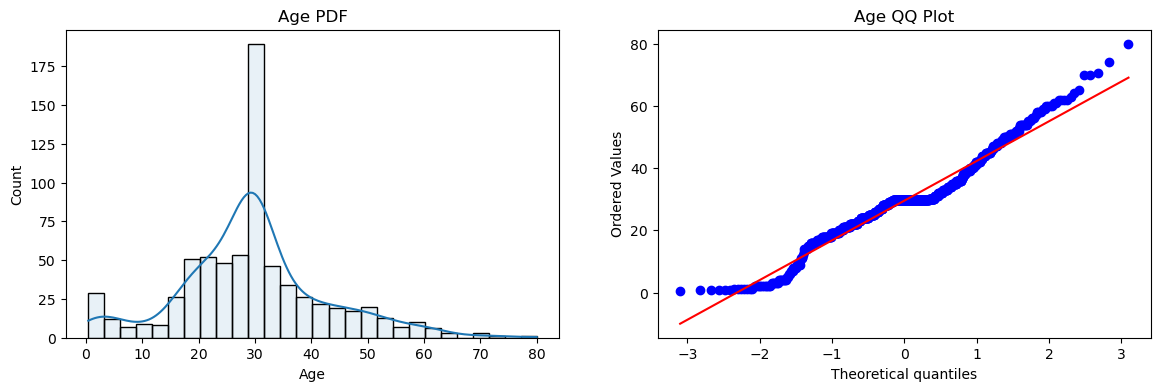

In [45]:
plt.figure(figsize=(14,4))

# Left subplot: Age distribution
plt.subplot(121)
sns.histplot(x_train['Age'], kde=True, alpha=0.1)  # kde=True gives PDF-like curve
plt.title('Age PDF')

# Right subplot: QQ plot
plt.subplot(122)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()


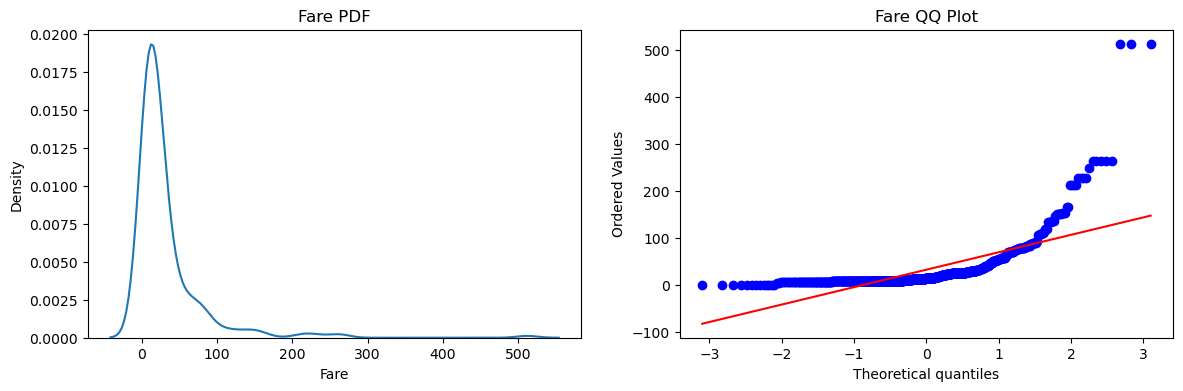

In [46]:
plt.figure(figsize=(14,4))

# Left subplot: Age distribution
plt.subplot(121)
sns.kdeplot(x_train['Fare'])
plt.title('Fare PDF')

# Right subplot: QQ plot
plt.subplot(122)
stats.probplot(x_train['Fare'], dist="norm", plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [47]:
print(data.skew())

Survived    0.478523
Age         0.434488
Fare        4.787317
dtype: float64


## as we can see skewness --> general thumb hand rule is if the value is between -0.5 to 0.5 then its considered moderate , if outside this range then high skewness 

#### and we can see here that survived and age are with in range -- so ok ,                              but fare is too skewed

## to see the effects we will first train model on raw then -- log transform -- then train model again

In [48]:
clf1 = LogisticRegression()
clf2 = DecisionTreeClassifier()

# making objects of these 

In [49]:
# train model

clf1.fit(x_train, y_train)

LogisticRegression()

In [50]:
clf2.fit(x_train, y_train)

DecisionTreeClassifier()

In [51]:
# predict

clf1.predict(x_test)

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0])

In [52]:
y_pred1 = clf1.predict(x_test)

In [53]:
y_pred2 = clf2.predict(x_test)

In [54]:
y_pred2

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 1])

In [55]:
# accuracy_score

print('Accuracy of LR : ', accuracy_score(y_test,y_pred1))
print('Accuracy of DT : ', accuracy_score(y_test,y_pred2))

Accuracy of LR :  0.6480446927374302
Accuracy of DT :  0.6815642458100558


In [56]:
# now lets do transformation

trf = FunctionTransformer(func= np.log1p)

In [57]:
x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

In [58]:
print(type(x_train_trf))
print(type(x_test_trf))


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


In [59]:
x_train_trf

,Age,Fare
331,3.839452,3.384390
733,3.178054,2.639057
382,3.496508,2.188856
704,3.295837,2.180892
813,1.945910,3.474293
...,...,...
106,3.091042,2.157559
270,3.424234,3.465736
860,3.737670,2.715244
435,2.708050,4.795791


In [60]:
# now again train and predict with model 

clf1.fit(x_train_trf, y_train)
clf2.fit(x_train_trf, y_train)


y_pred3 = clf1.predict(x_test_trf)
y_pred4 = clf2.predict(x_test_trf)


print('Accuracy of transformed LR : ', accuracy_score(y_test,y_pred3))
print('Accuracy of transformed DT : ', accuracy_score(y_test,y_pred4))


Accuracy of transformed LR :  0.6815642458100558
Accuracy of transformed DT :  0.6815642458100558


In [63]:
# lets cross validate to check if score actually improved

x_transformed = trf.fit_transform(x)


clf1 = LogisticRegression()
clf2 = DecisionTreeClassifier()


print('Accuracy of transformed LR :', np.mean(cross_val_score(clf1, x_transformed, y, scoring='accuracy', cv=10)))
print('Accuracy of transformed DT :', np.mean(cross_val_score(clf2, x_transformed, y, scoring='accuracy', cv=10)))

Accuracy of transformed LR : 0.678027465667915
Accuracy of transformed DT : 0.6577153558052434


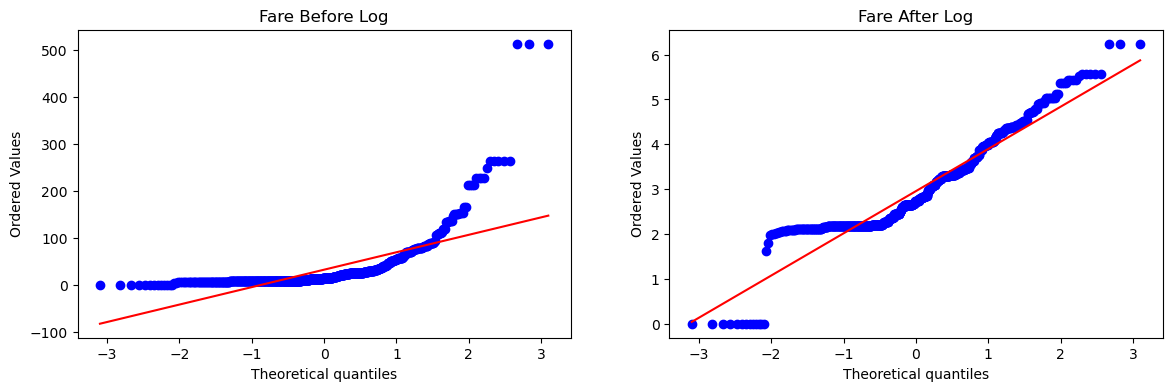

In [65]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(x_train_trf['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

In [66]:
# we got improvement in fare after log 

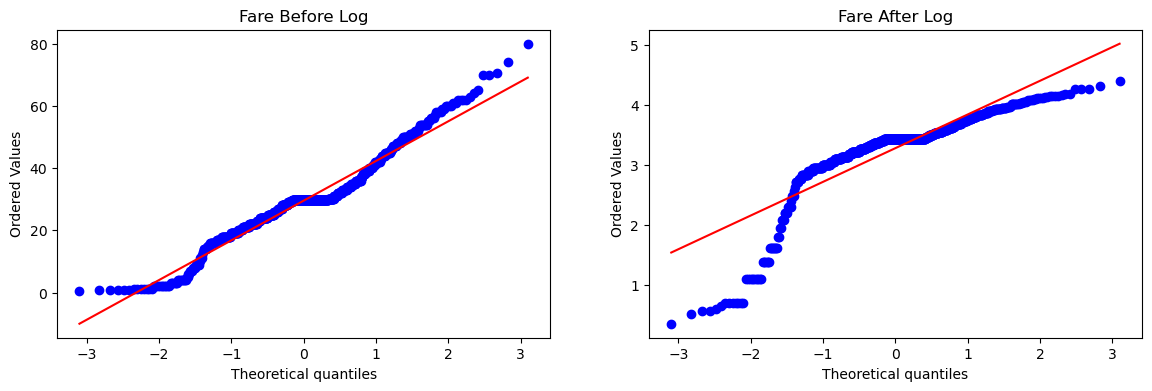

In [67]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(x_train_trf['Age'], dist="norm", plot=plt)
plt.title('Fare After Log')

plt.show()

In [68]:
# now we can see that age got worsed , so we dont need to log this col, and we see in value also its 
# distribution was less than 0.5

In [69]:
x.skew()

Age     0.434488
Fare    4.787317
dtype: float64

In [70]:
x_transformed.skew()

Age    -2.217104
Fare    0.394928
dtype: float64

In [71]:
# so our ideal scenario will be only transform fare and not age ✅

In [88]:
data.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


# function transformations --> reciprocal / sq / sq-root / custom

In [93]:
def apply_transfomr(transform):
    X = data.drop(columns=['Survived'])
    Y = data['Survived']
    
    
    trf = ColumnTransformer(transformers=[
        ('log', FunctionTransformer(transform),['Fare'])
    ], remainder='passthrough')
    
    
    X_trf = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print('Accuracy of LR before transformation : ',
         np.mean(cross_val_score(clf, X,Y, scoring='accuracy', cv=10)))
    
    print('Accuracy of LR after transformation : ',
         np.mean(cross_val_score(clf, X_trf,Y, scoring='accuracy', cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trf[:, 0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.6589013732833957


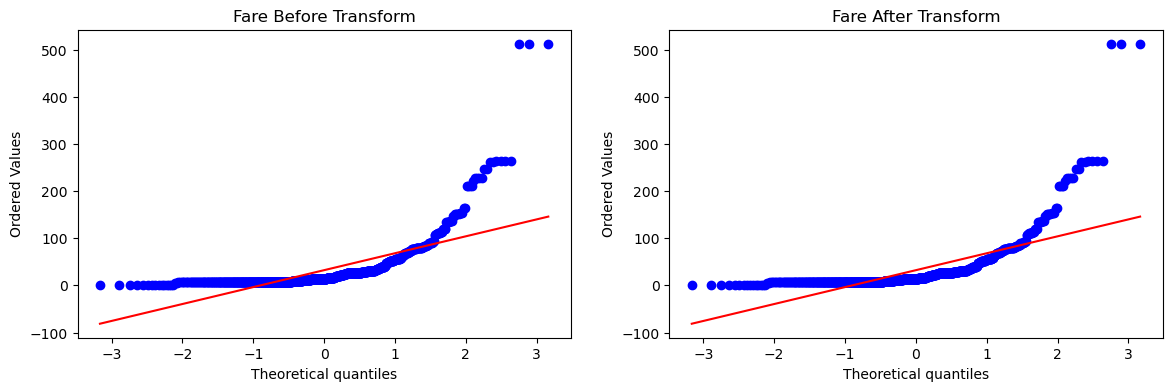

In [94]:
apply_transfomr(lambda x : x)

In [95]:
# obviously , since we gave no transformation : x=x

## square transform


Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.6431335830212235


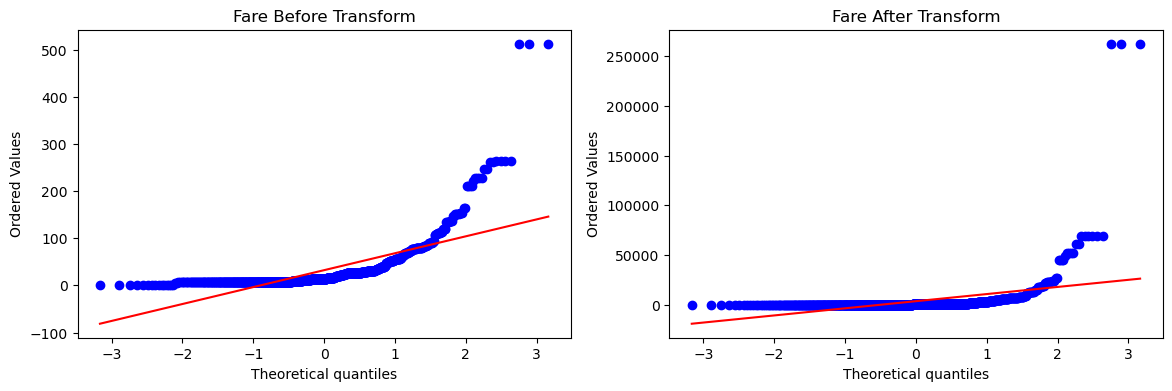

In [96]:
apply_transfomr(lambda x : x**2)

In [82]:
# hmm , now we can see the difference , since this fare is an right skewed data and not suitable for sq transform

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.44563046192259675


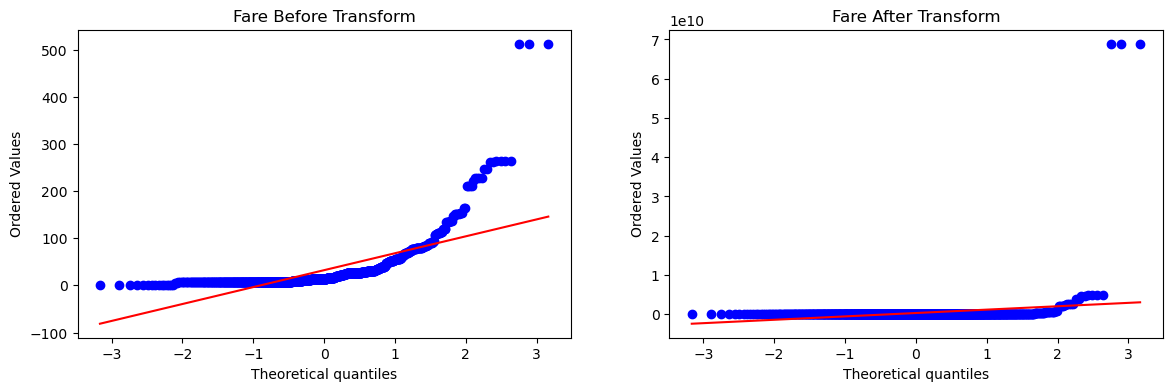

In [97]:
# lets try with cube -- obviously it will be worse

apply_transfomr(lambda x : x**4)

## square root

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.6589013732833957


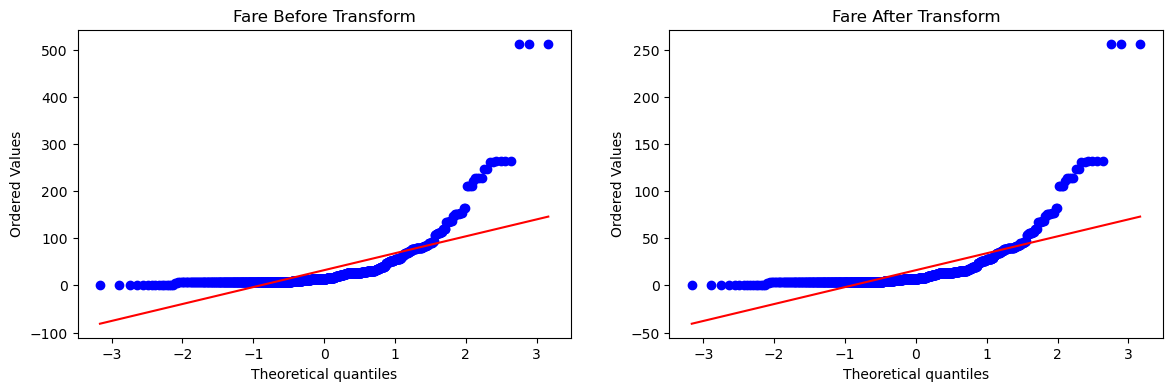

In [98]:
apply_transfomr(lambda x : x**1/2)

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.6589013732833957


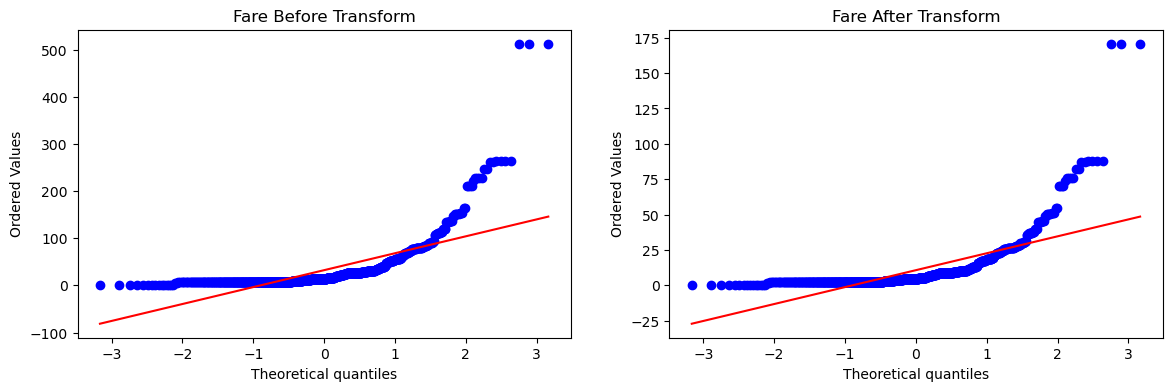

In [99]:
apply_transfomr(lambda x : x**1/3)

In [100]:
# no difference

## reciprocal

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.61729088639201


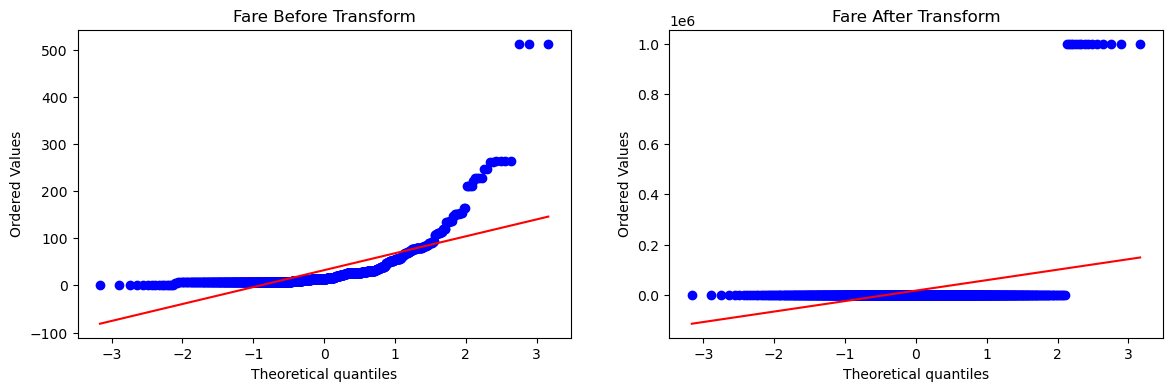

In [102]:
apply_transfomr(lambda x : 1/(x+0.000001))

## custom -- now you can give any value

Accuracy of LR before transformation :  0.6589013732833957
Accuracy of LR after transformation :  0.6195131086142323


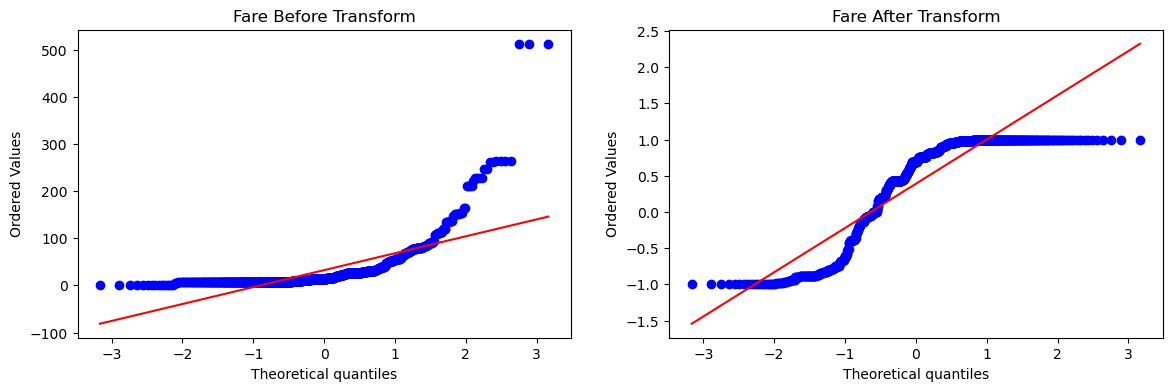

In [103]:
apply_transfomr(np.sin)

In [104]:
# all set ✅